# 09 — Error Analysis

## Objective

This notebook analyzes the mistakes made by the finalized customer churn prediction model.

The goal is to understand which customers are incorrectly classified and whether prediction errors are concentrated in specific customer segments.

The model architecture, hyperparameters and classification threshold are already finalized.

This analysis is diagnostic only and will not be used to modify the model or optimize test performance.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier

In [2]:
PROJECT_ROOT = Path("..")

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "WA_FnUseC_TelcoCustomerChurn.csv"
)

df = pd.read_csv(DATA_PATH)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [3]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    column
    for column in X_train.columns
    if column not in numeric_features
]

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [4]:
FINAL_THRESHOLD = 0.35

final_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            GradientBoostingClassifier(
                n_estimators=300,
                learning_rate=0.1,
                max_depth=1,
                min_samples_leaf=1,
                random_state=42
            )
        )
    ]
)

final_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

In [5]:
class_labels = list(
    final_model.named_steps["classifier"].classes_
)

positive_class_index = class_labels.index("Yes")

test_probabilities = final_model.predict_proba(
    X_test
)[:, positive_class_index]

test_predictions = np.where(
    test_probabilities >= FINAL_THRESHOLD,
    "Yes",
    "No"
)

In [6]:
error_analysis = X_test.copy()

error_analysis["actual"] = y_test.values
error_analysis["predicted"] = test_predictions
error_analysis["churn_probability"] = test_probabilities

In [7]:
conditions = [
    (
        (error_analysis["actual"] == "Yes")
        & (error_analysis["predicted"] == "Yes")
    ),
    (
        (error_analysis["actual"] == "No")
        & (error_analysis["predicted"] == "No")
    ),
    (
        (error_analysis["actual"] == "No")
        & (error_analysis["predicted"] == "Yes")
    ),
    (
        (error_analysis["actual"] == "Yes")
        & (error_analysis["predicted"] == "No")
    )
]

labels = [
    "True Positive",
    "True Negative",
    "False Positive",
    "False Negative"
]

error_analysis["outcome"] = np.select(
    conditions,
    labels,
    default="Unknown"
)

In [8]:
error_analysis["outcome"].value_counts()

outcome
True Negative     823
True Positive     270
False Positive    212
False Negative    104
Name: count, dtype: int64

In [9]:
error_analysis["distance_to_threshold"] = (
    error_analysis["churn_probability"]
    - FINAL_THRESHOLD
).abs()

In [10]:
error_analysis.groupby(
    "outcome"
)[
    [
        "churn_probability",
        "distance_to_threshold"
    ]
].agg(
    ["mean", "median"]
).round(4)

churn_probability         distance_to_threshold        
                            mean  median                  mean  median
outcome                                                               
False Negative            0.1967  0.1904                0.1533  0.1596
False Positive            0.5148  0.4924                0.1648  0.1424
True Negative             0.1010  0.0607                0.2490  0.2893
True Positive             0.6078  0.5945                0.2578  0.2445

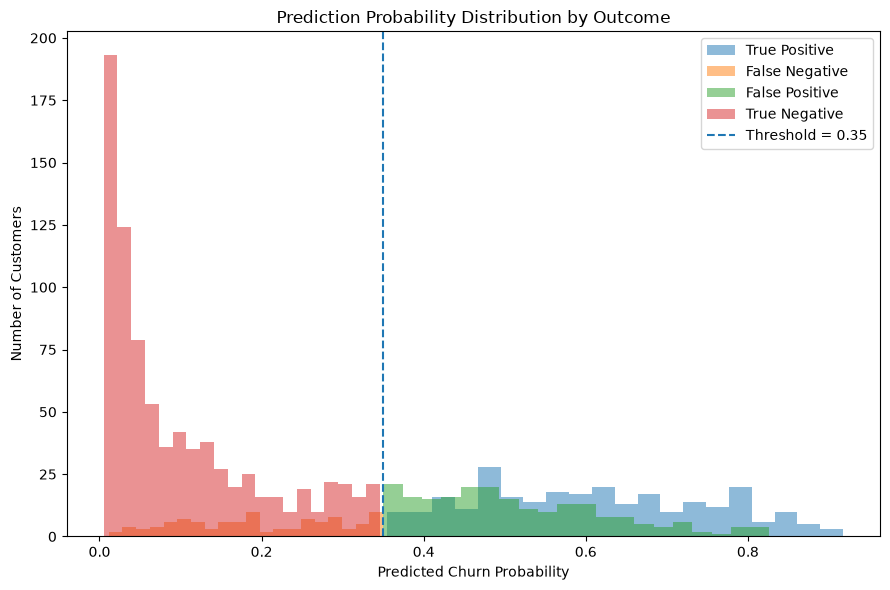

In [11]:
plt.figure(figsize=(9, 6))

for outcome in [
    "True Positive",
    "False Negative",
    "False Positive",
    "True Negative"
]:
    subset = error_analysis[
        error_analysis["outcome"] == outcome
    ]

    plt.hist(
        subset["churn_probability"],
        bins=20,
        alpha=0.5,
        label=outcome
    )

plt.axvline(
    FINAL_THRESHOLD,
    linestyle="--",
    label="Threshold = 0.35"
)

plt.xlabel("Predicted Churn Probability")
plt.ylabel("Number of Customers")
plt.title("Prediction Probability Distribution by Outcome")

plt.legend()
plt.tight_layout()
plt.show()

In [12]:
false_negatives = error_analysis[
    error_analysis["outcome"]
    == "False Negative"
]

false_positives = error_analysis[
    error_analysis["outcome"]
    == "False Positive"
]

In [13]:
false_negatives[
    [
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "Contract",
        "InternetService",
        "OnlineSecurity",
        "TechSupport",
        "PaymentMethod",
        "churn_probability"
    ]
].describe(include="all")

,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,OnlineSecurity,TechSupport,PaymentMethod,churn_probability
count,104.000000,104.000000,104.000000,104,104,104,104,104,104.000000
unique,NaN,NaN,NaN,3,3,3,3,4,NaN
top,NaN,NaN,NaN,Month-to-month,DSL,No,No,Electronic check,NaN
freq,NaN,NaN,NaN,61,45,44,49,30,NaN
mean,29.509615,64.422115,2409.259615,NaN,NaN,NaN,NaN,NaN,0.196688
std,22.597360,30.283795,2363.967259,NaN,NaN,NaN,NaN,NaN,0.096609
min,1.000000,18.950000,19.300000,NaN,NaN,NaN,NaN,NaN,0.011443
25%,7.000000,45.825000,232.550000,NaN,NaN,NaN,NaN,NaN,0.112987
50%,26.500000,60.375000,1737.125000,NaN,NaN,NaN,NaN,NaN,0.190406
75%,49.250000,92.862500,3765.062500,NaN,NaN,NaN,NaN,NaN,0.281782


In [14]:
false_positives[
    [
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "Contract",
        "InternetService",
        "OnlineSecurity",
        "TechSupport",
        "PaymentMethod",
        "churn_probability"
    ]
].describe(include="all")

,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,OnlineSecurity,TechSupport,PaymentMethod,churn_probability
count,212.000000,212.000000,212.000000,212,212,212,212,212,212.000000
unique,NaN,NaN,NaN,2,3,3,3,4,NaN
top,NaN,NaN,NaN,Month-to-month,Fiber optic,No,No,Electronic check,NaN
freq,NaN,NaN,NaN,208,153,170,170,125,NaN
mean,16.891509,75.220519,1515.691981,NaN,NaN,NaN,NaN,NaN,0.514820
std,17.163902,23.974470,1739.086258,NaN,NaN,NaN,NaN,NaN,0.116692
min,1.000000,18.800000,18.800000,NaN,NaN,NaN,NaN,NaN,0.350292
25%,3.000000,58.600000,211.150000,NaN,NaN,NaN,NaN,NaN,0.423444
50%,10.000000,79.700000,754.650000,NaN,NaN,NaN,NaN,NaN,0.492404
75%,24.000000,94.062500,2167.087500,NaN,NaN,NaN,NaN,NaN,0.595323


In [15]:
pd.crosstab(
    error_analysis["Contract"],
    error_analysis["outcome"],
    normalize="index"
).round(3)

outcome,False Negative,False Positive,True Negative,True Positive
Contract,,,,
Month-to-month,0.079,0.269,0.305,0.347
One year,0.113,0.013,0.867,0.007
Two year,0.027,0.000,0.973,0.000


In [16]:
pd.crosstab(
    error_analysis["InternetService"],
    error_analysis["outcome"],
    normalize="index"
).round(3)

outcome,False Negative,False Positive,True Negative,True Positive
InternetService,,,,
DSL,0.093,0.097,0.702,0.107
Fiber optic,0.064,0.250,0.339,0.347
No,0.064,0.038,0.881,0.016


In [17]:
error_analysis["tenure_group"] = pd.cut(
    error_analysis["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        "0-6 months",
        "7-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

pd.crosstab(
    error_analysis["tenure_group"],
    error_analysis["outcome"],
    normalize="index"
).round(3)

outcome,False Negative,False Positive,True Negative,True Positive
tenure_group,,,,
0-6 months,0.077,0.264,0.180,0.479
7-12 months,0.094,0.246,0.449,0.210
13-24 months,0.063,0.218,0.490,0.228
25-48 months,0.089,0.115,0.674,0.122
49-72 months,0.060,0.036,0.887,0.018


In [18]:
error_analysis["outcome"].value_counts()

outcome
True Negative     823
True Positive     270
False Positive    212
False Negative    104
Name: count, dtype: int64

In [19]:
error_analysis.groupby(
    "outcome"
)[
    [
        "churn_probability",
        "distance_to_threshold"
    ]
].agg(
    ["mean", "median"]
).round(4)

churn_probability         distance_to_threshold        
                            mean  median                  mean  median
outcome                                                               
False Negative            0.1967  0.1904                0.1533  0.1596
False Positive            0.5148  0.4924                0.1648  0.1424
True Negative             0.1010  0.0607                0.2490  0.2893
True Positive             0.6078  0.5945                0.2578  0.2445

In [20]:
pd.crosstab(
    error_analysis["Contract"],
    error_analysis["outcome"],
    normalize="index"
).round(3)

outcome,False Negative,False Positive,True Negative,True Positive
Contract,,,,
Month-to-month,0.079,0.269,0.305,0.347
One year,0.113,0.013,0.867,0.007
Two year,0.027,0.000,0.973,0.000


In [21]:
def segment_error_rates(data, column):
    rows = []

    for value, group in data.groupby(column, observed=False):
        tp = (
            (group["actual"] == "Yes")
            & (group["predicted"] == "Yes")
        ).sum()

        fn = (
            (group["actual"] == "Yes")
            & (group["predicted"] == "No")
        ).sum()

        fp = (
            (group["actual"] == "No")
            & (group["predicted"] == "Yes")
        ).sum()

        tn = (
            (group["actual"] == "No")
            & (group["predicted"] == "No")
        ).sum()

        false_negative_rate = (
            fn / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        )

        false_positive_rate = (
            fp / (fp + tn)
            if (fp + tn) > 0
            else np.nan
        )

        rows.append({
            "segment": value,
            "customers": len(group),
            "true_positives": tp,
            "false_negatives": fn,
            "false_negative_rate": false_negative_rate,
            "false_positives": fp,
            "true_negatives": tn,
            "false_positive_rate": false_positive_rate
        })

    return pd.DataFrame(rows)

In [22]:
contract_error_rates = segment_error_rates(
    error_analysis,
    "Contract"
)

contract_error_rates.round(4)

,segment,customers,true_positives,false_negatives,false_negative_rate,false_positives,true_negatives,false_positive_rate
0,Month-to-month,773,268,61,0.1854,208,236,0.4685
1,One year,300,2,34,0.9444,4,260,0.0152
2,Two year,336,0,9,1.0000,0,327,0.0000


In [23]:
internet_error_rates = segment_error_rates(
    error_analysis,
    "InternetService"
)

internet_error_rates.round(4)

,segment,customers,true_positives,false_negatives,false_negative_rate,false_positives,true_negatives,false_positive_rate
0,DSL,484,52,45,0.4639,47,340,0.1214
1,Fiber optic,613,213,39,0.1548,153,208,0.4238
2,No,312,5,20,0.8000,12,275,0.0418


In [24]:
tenure_error_rates = segment_error_rates(
    error_analysis,
    "tenure_group"
)

tenure_error_rates.round(4)

,segment,customers,true_positives,false_negatives,false_negative_rate,false_positives,true_negatives,false_positive_rate
0,0-6 months,311,149,24,0.1387,82,56,0.5942
1,7-12 months,138,29,13,0.3095,34,62,0.3542
2,13-24 months,206,47,13,0.2167,45,101,0.3082
3,25-48 months,304,37,27,0.4219,35,205,0.1458
4,49-72 months,450,8,27,0.7714,16,399,0.0386


## Initial Error Analysis Findings

The final confusion matrix contains 823 true negatives, 270 true positives, 212 false positives and 104 false negatives.

Prediction confidence differs substantially across outcome groups. Correctly retained customers receive very low churn probabilities on average, while correctly identified churners receive considerably higher probabilities.

False negatives have an average predicted churn probability well below the selected threshold. This suggests that many missed churners are not simply borderline classification cases; some customers who eventually churn exhibit characteristics that the model strongly associates with retention.

False positives show moderately high churn probabilities, indicating that some retained customers share characteristics commonly associated with churn.

Contract type also produces distinct error patterns. Month-to-month customers generate both many true-positive detections and a substantial number of false-positive alerts, consistent with contract type being one of the strongest predictive features.

Further segment-level error rates are required to distinguish overall segment composition from conditional false-negative and false-positive rates.

## Error Analysis Conclusions

The final model exhibits systematic error patterns that are consistent with the predictive relationships identified during model interpretation.

The model performs particularly well at detecting churn among customers with characteristics strongly associated with churn, such as month-to-month contracts, short tenure and fiber-optic internet service.

However, these same patterns also generate a substantial number of false positives. For example, month-to-month and short-tenure customers are frequently classified as high risk even when they ultimately remain with the company.

The opposite pattern appears among customers associated with lower churn risk. Churners with one-year or two-year contracts, long tenure or no internet service are much more likely to be missed by the model.

This indicates that many model errors are not simply borderline threshold cases. Instead, the model sometimes assigns strong confidence to an incorrect prediction when a customer behaves differently from the dominant patterns learned from the training data.

These results highlight an important limitation of the model: strong segment-level associations improve overall predictive performance but can also create systematic blind spots for atypical customers.

Segment-level error rates should also be interpreted with sample size in mind. Some subgroups contain relatively few actual churners, making their error-rate estimates less stable.

This analysis is diagnostic only. No model, hyperparameter or threshold changes are made after examining held-out test errors.